In [1]:
import os
import numpy as np
import pandas as pd
import sys
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib import transforms
import seaborn as sns

sys.path.append('/home/sandor_daniel/work/2023-11-08_cont_opt_grn/golem/src')

import logging
from utils.utils import count_accuracy, set_seed


conf_cmap = ListedColormap(['white', 'green', 'lightcoral', 'red'])

from models import GolemModel
from trainers import GolemTrainer

2023-11-13 14:22:14.554263: I tensorflow/core/util/port.cc:110] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2023-11-13 14:22:14.618523: I tensorflow/core/platform/cpu_feature_guard.cc:182] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: SSE4.1 SSE4.2 AVX AVX2 AVX512F AVX512_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


In [7]:
def load_standard(directory):
    standard = [pd.read_csv(f'{directory}/{file}', sep='\t', header=None) for file in sorted(os.listdir(directory)) if file.endswith('.tsv')]
    for i in range(len(standard)):
        standard[i].replace([f'G{i}' for i in range(10)], [f'G0{i}' for i in range(10)], inplace=True)
        standard[i] = standard[i].pivot(columns=[0], index=[1], values=[2])
        np.fill_diagonal(standard[i].values, 0)
        standard[i] = standard[i].to_numpy()
    return standard

def load_data(directory, condition):
    data = [np.loadtxt(f'{directory}/{folder}/{folder}_timeseries.tsv', skiprows=1)[:,1:] for folder in sorted(os.listdir(directory)) if condition(folder)]
    return data

def calc_vars(data):
    return [data.var(axis=0) for data in data]

def load_preds(directory):
    preds = []
    for file in sorted(os.listdir(directory)):
        g = np.loadtxt(f'{directory}/{file}', delimiter=',')
        preds.append(g)
    return preds

def calc_residual_var(data, preds):
    vars = []
    for i in range(len(data)):
        data_hat = np.matmul(data[i], preds[i])
        vars.append(np.var(data[i] - data_hat, axis=0))
    return vars

def print_metrics(standard, preds):
    for (p, s) in zip(preds, standard):
        results = count_accuracy(s != 0, p != 0)
        print(results)

def plot_heatmap(standard, preds, vars):
    for i in range(len(standard)):
        preds_dag = (preds[i] != 0).astype(int)
        c_mtx = np.zeros_like(standard[i])
        c_mtx[np.logical_and(standard[i] == preds_dag, standard[i] == 0)] = 0 # TN
        c_mtx[np.logical_and(standard[i] == preds_dag, standard[i] == 1)] = 1 # TP
        c_mtx[np.logical_and(standard[i] != preds_dag, standard[i] == 1)] = 2 # FN
        c_mtx[np.logical_and(standard[i] != preds_dag, standard[i] == 0)] = 3 # FP
        
        plt.figure(figsize=standard[i].shape)
        plt.subplot(2, 2, 3)
        sns.heatmap(c_mtx, annot=True, fmt='g', cmap=conf_cmap, cbar=False)
        plt.subplot(2, 2, 1)
        sns.barplot(vars[i])
        plt.subplot(2, 2, 4)
        sns.barplot(vars[i], orient='h')
        plt.show()

In [3]:
dream4_standard_10 = load_standard('DREAM4/DREAM4_Challenge2_GoldStandards/Size 10')
dream4_data_10 = load_data('DREAM4', lambda folder: 'size10_' in folder)
dream4_data_10_vars = calc_vars(dream4_data_10)

dream4_standard_100 = load_standard('DREAM4/DREAM4_Challenge2_GoldStandards/Size 100')
dream4_data_100 = load_data('DREAM4', lambda folder: 'size100_' in folder and 'multifactorial' not in folder)
dream4_data_100_vars = calc_vars(dream4_data_100)

preds_golem_ev_10 = load_preds('out/dream4_10/golem_ev/')
preds_golem_ev_100 = load_preds('out/dream4_100/golem_ev/')
preds_notears_10 = load_preds('out/dream4_10/notears/')

In [4]:
print('DREAM4 10 - GOLEM EV')
print_metrics(dream4_standard_10, preds_golem_ev_10)
print('DREAM4 100 - GOLEM EV')
print_metrics(dream4_standard_100, preds_golem_ev_100)
print('DREAM4 10 - NOTEARS')
print_metrics(dream4_standard_10, preds_notears_10)

DREAM4 10 - GOLEM EV
{'fdr': 0.5714285714285714, 'tpr': 0.8666666666666667, 'fpr': 0.4, 'shd': 16, 'pred_size': 21}
{'fdr': 0.6818181818181818, 'tpr': 0.9375, 'fpr': 0.5172413793103449, 'shd': 20, 'pred_size': 22}
{'fdr': 0.6470588235294118, 'tpr': 0.4, 'fpr': 0.36666666666666664, 'shd': 18, 'pred_size': 17}
{'fdr': 0.7307692307692307, 'tpr': 0.5384615384615384, 'fpr': 0.59375, 'shd': 22, 'pred_size': 26}
{'fdr': 0.75, 'tpr': 0.4166666666666667, 'fpr': 0.45454545454545453, 'shd': 19, 'pred_size': 20}
DREAM4 100 - GOLEM EV
{'fdr': 0.9805825242718447, 'tpr': 0.10227272727272728, 'fpr': 0.042312526183493925, 'shd': 365, 'pred_size': 206}
{'fdr': 0.9625668449197861, 'tpr': 0.08433734939759036, 'fpr': 0.03828972559029994, 'shd': 407, 'pred_size': 187}
{'fdr': 0.9723756906077348, 'tpr': 0.05641025641025641, 'fpr': 0.0370136698212408, 'shd': 359, 'pred_size': 181}
{'fdr': 0.9790575916230366, 'tpr': 0.05687203791469194, 'fpr': 0.03945980164591686, 'shd': 387, 'pred_size': 191}
{'fdr': 0.994845

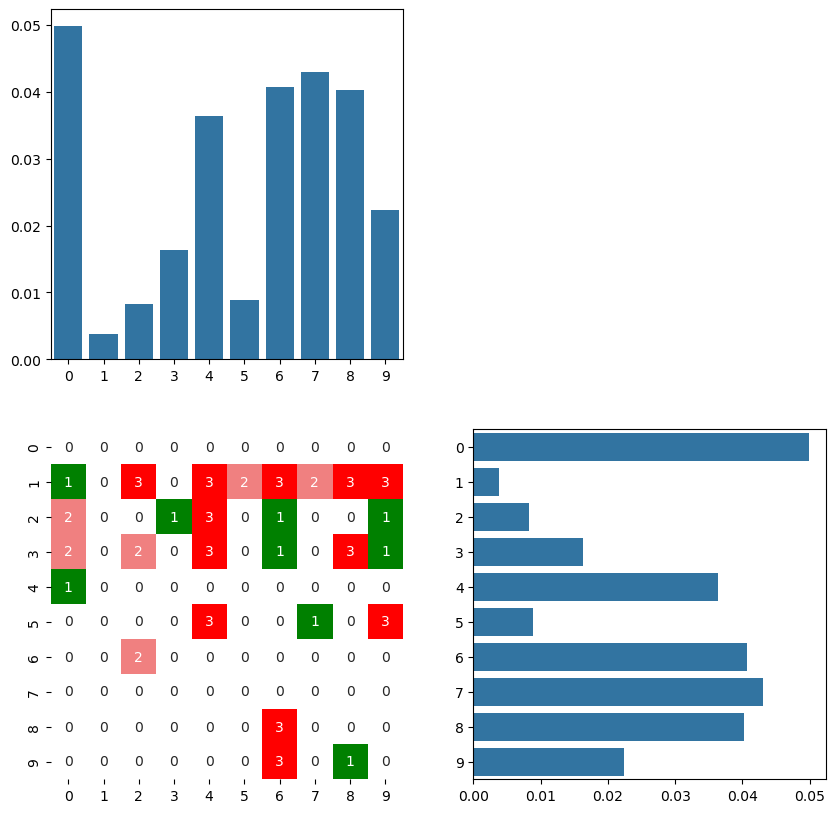

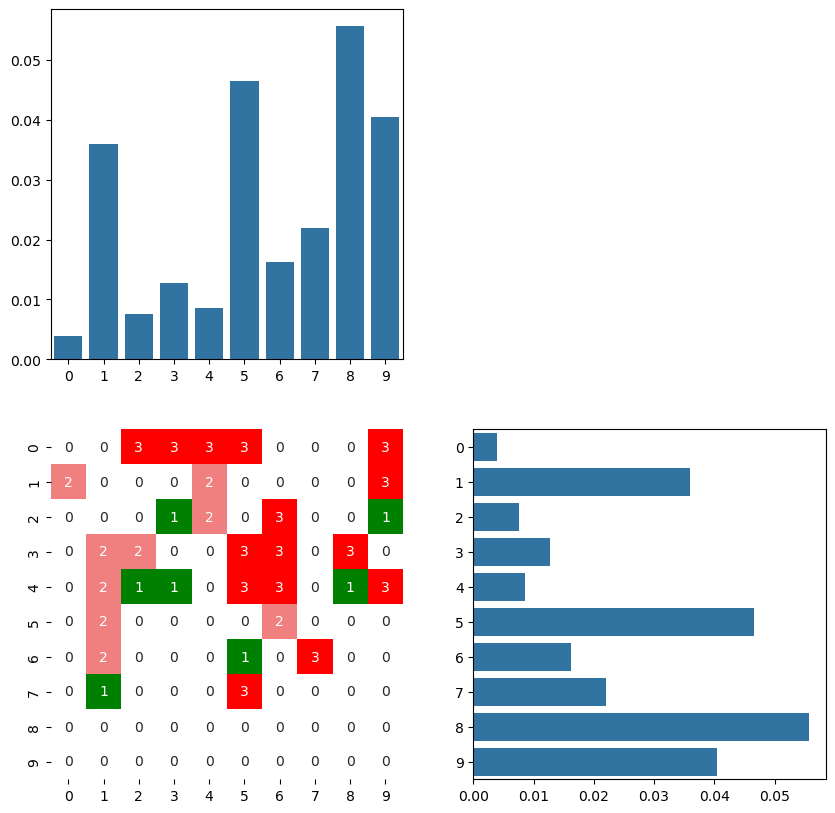

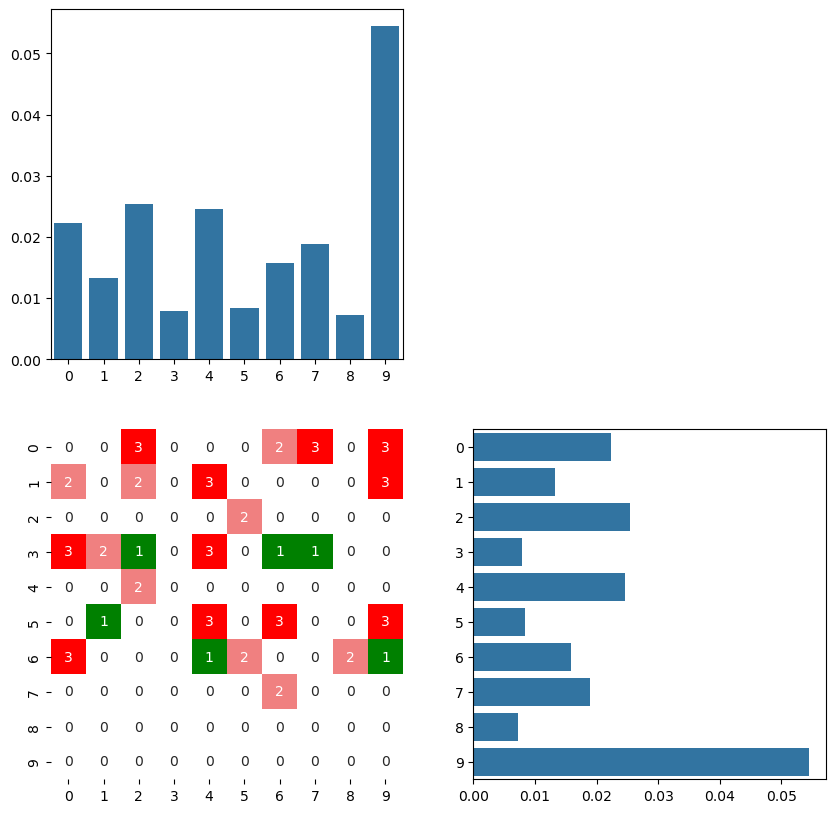

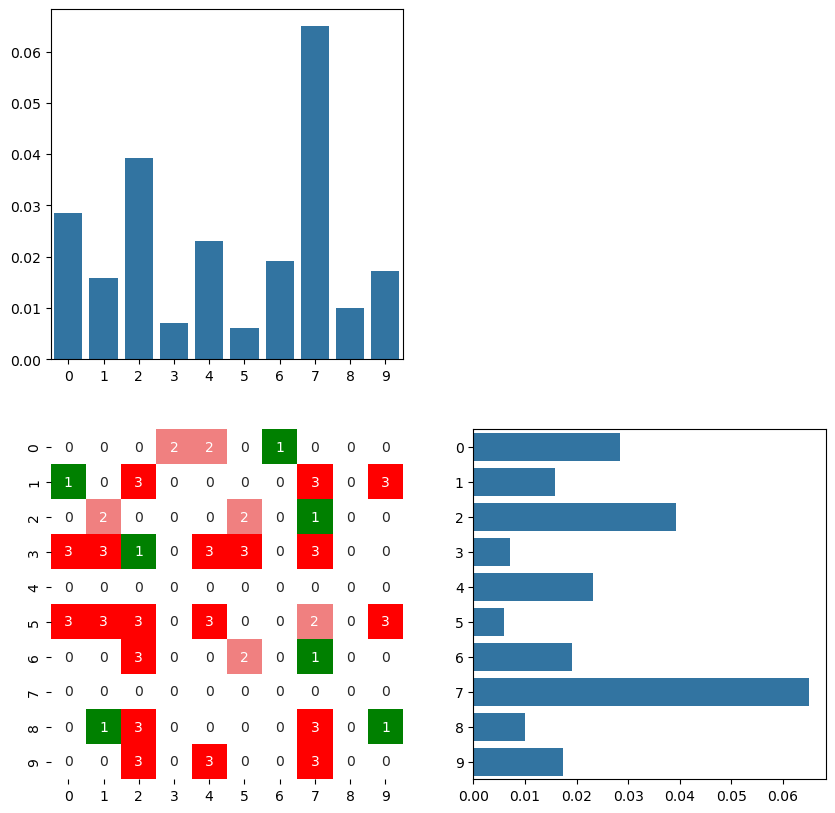

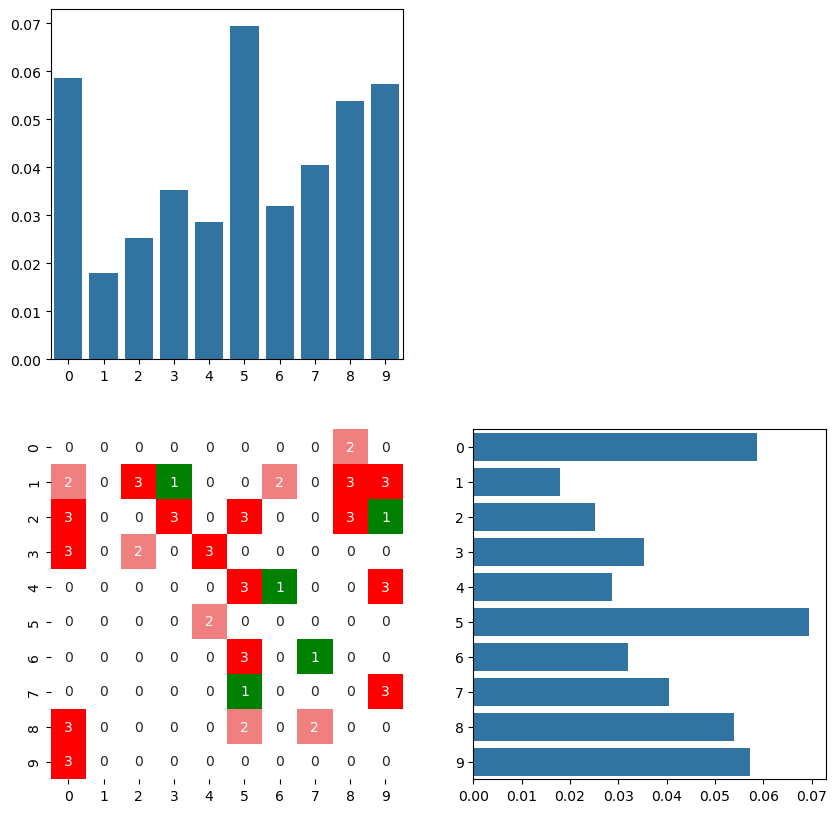

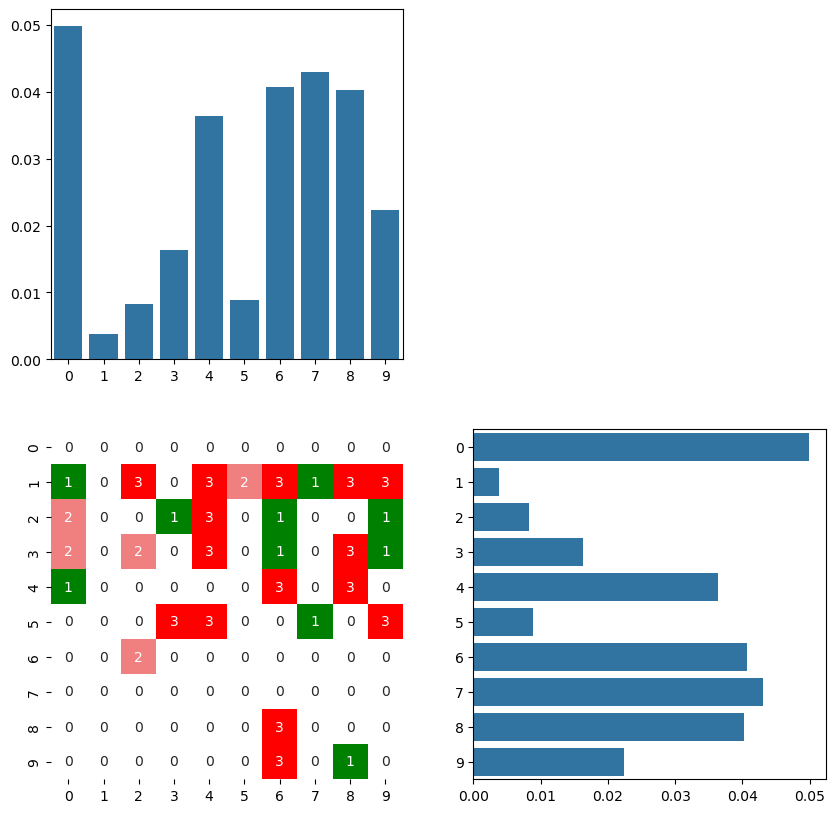

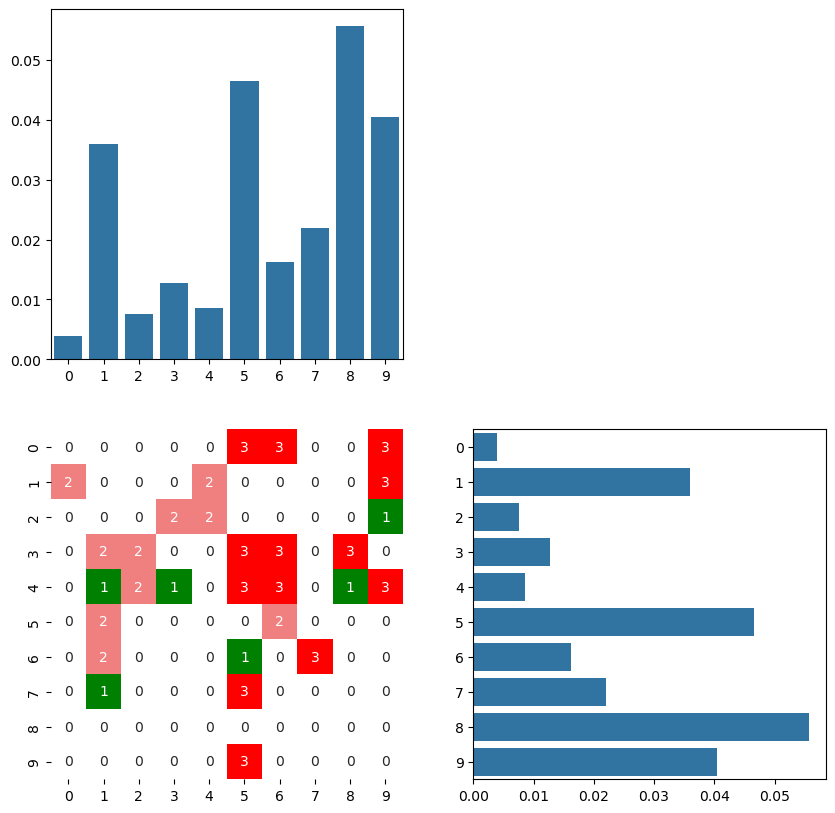

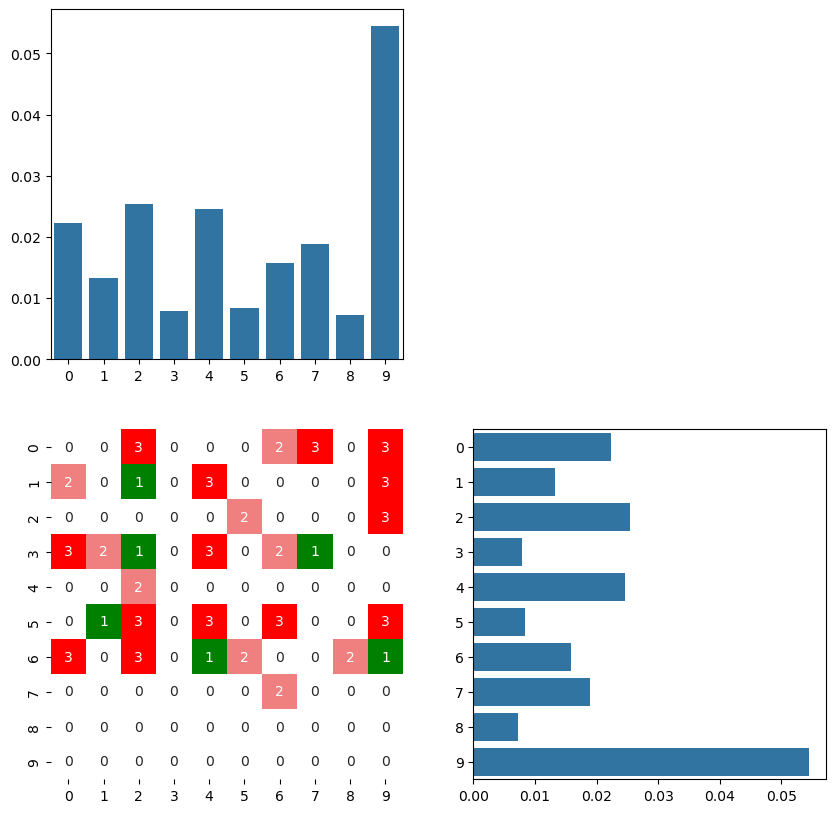

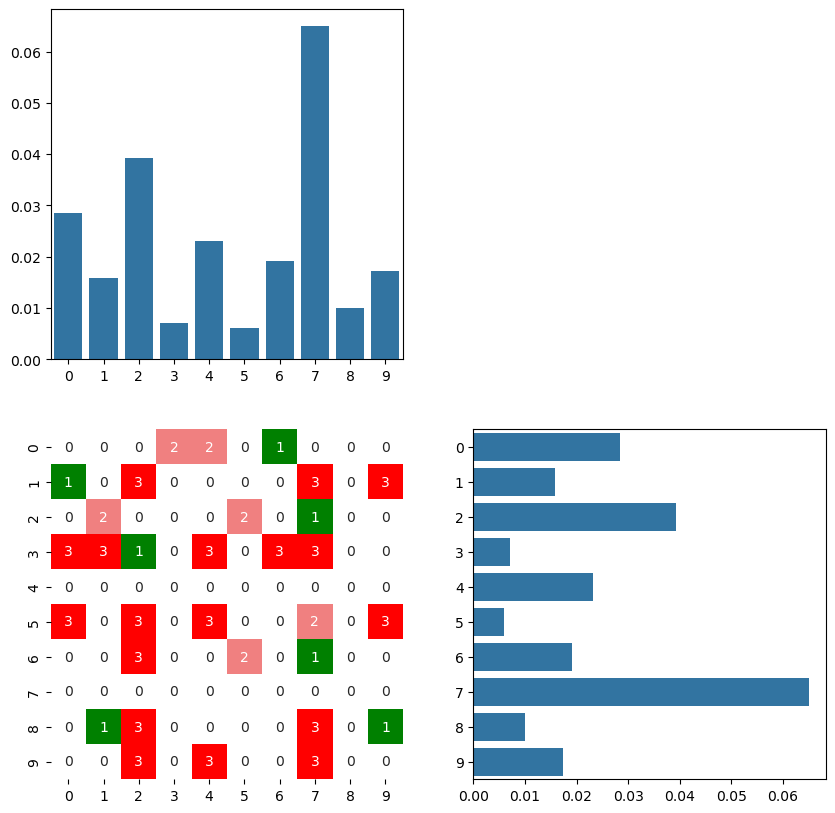

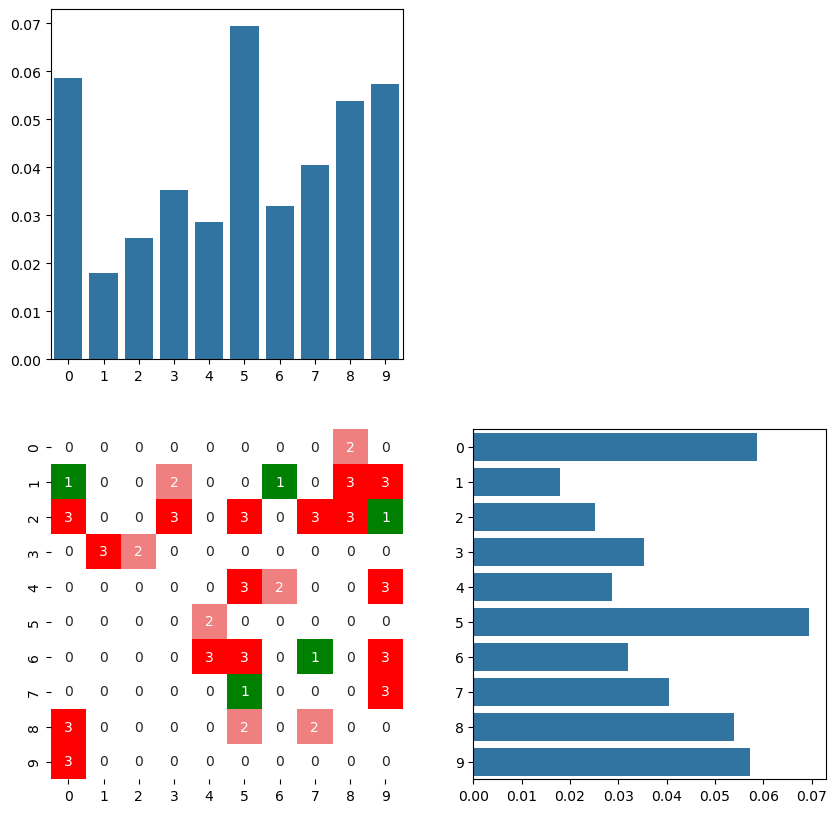

In [8]:
plot_heatmap(dream4_standard_10, preds_golem_ev_10, dream4_data_10_vars)
plot_heatmap(dream4_standard_100, preds_golem_ev_100, dream4_data_100_vars)
plot_heatmap(dream4_standard_10, preds_notears_10, dream4_data_10_vars)

In [26]:
res_vars_golem_ev_10 = calc_residual_var(dream4_data_10, preds_golem_ev_10)
res_vars_golem_ev_100 = calc_residual_var(dream4_data_100, preds_golem_ev_100)
res_vars_notears_10 = calc_residual_var(dream4_data_10, preds_notears_10)

In [29]:
def calc_source_sink_score(dag_w):
    source_score = np.sum(np.absolute(dag_w), axis=0)
    sink_score = np.sum(np.absolute(dag_w), axis=1)
    return source_score - sink_score

In [40]:
sosi_golem_ev_10 = [calc_source_sink_score(pred) for pred in preds_golem_ev_10] 
sosi_golem_ev_100 = [calc_source_sink_score(pred) for pred in preds_golem_ev_100]
sosi_notears_10 = [calc_source_sink_score(pred) for pred in preds_notears_10]

sosi_dream4_10 = [calc_source_sink_score(standard) for standard in dream4_standard_10] 
sosi_dream4_100 = [calc_source_sink_score(standard) for standard in dream4_standard_100]

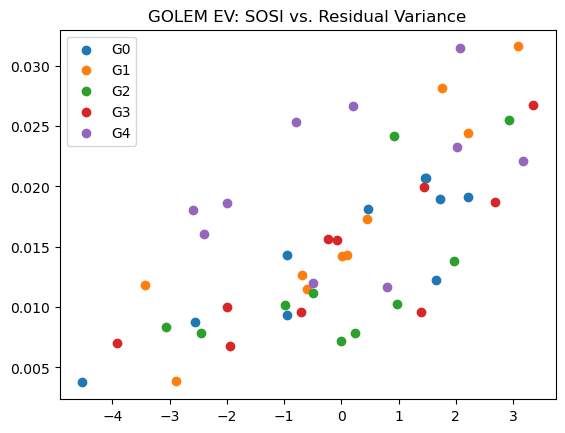

0.7373491316592226


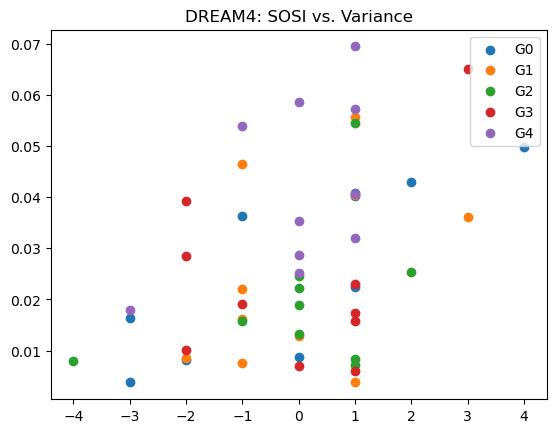

0.4682808955018988


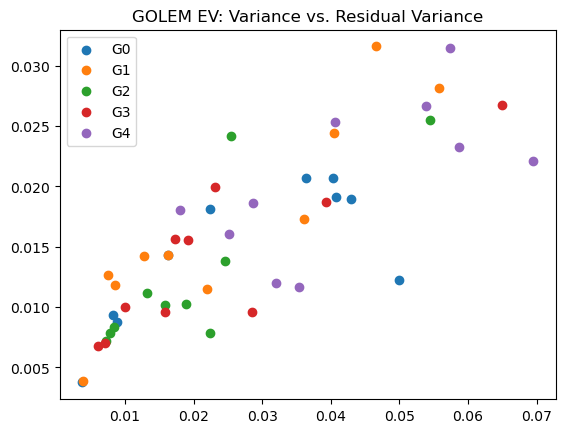

0.79366178624289


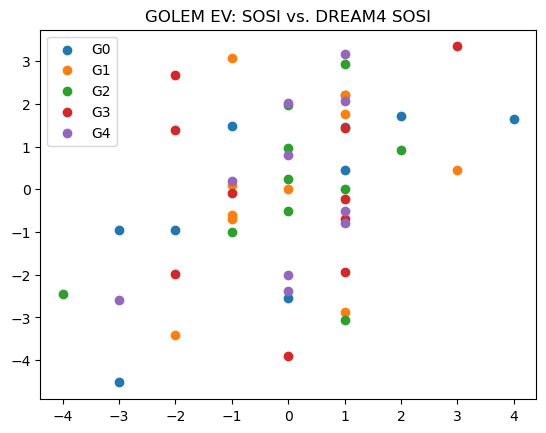

0.411335598537947


In [61]:
for i in range(5):
    plt.scatter(sosi_golem_ev_10[i], res_vars_golem_ev_10[i], label=f'G{i}')
    plt.legend()
plt.title('GOLEM EV: SOSI vs. Residual Variance')
plt.show()
print(np.mean([np.corrcoef(sosi, var)[0,1] for (sosi, var) in zip(sosi_golem_ev_10, res_vars_golem_ev_10)]))

for i in range(5):
    plt.scatter(sosi_dream4_10[i], dream4_data_10_vars[i], label=f'G{i}')
    plt.legend()
plt.title('DREAM4: SOSI vs. Variance')
plt.show()
print(np.mean([np.corrcoef(sosi, var)[0,1] for (sosi, var) in zip(sosi_dream4_10, dream4_data_10_vars)]))

for i in range(5):
    plt.scatter(dream4_data_10_vars[i], res_vars_golem_ev_10[i], label=f'G{i}')
    plt.legend()
plt.title('GOLEM EV: Variance vs. Residual Variance')
plt.show()
print(np.mean([np.corrcoef(var, res_var)[0,1] for (var, res_var) in zip(dream4_data_10_vars, res_vars_golem_ev_10)]))

for i in range(5):
    plt.scatter(sosi_dream4_10[i], sosi_golem_ev_10[i], label=f'G{i}')
    plt.legend()
plt.title('GOLEM EV: SOSI vs. DREAM4 SOSI')
plt.show()
print(np.mean([np.corrcoef(sosi, sosi_golem)[0,1] for (sosi, sosi_golem) in zip(sosi_dream4_10, sosi_golem_ev_10)]))


In [54]:
sosi_golem_ev_10[0].shape

(10,)